# Version finale - 2. Modèle de patch, lames entières et patientes


Ce notebook reprend la chaîne du prototype, sur les données de la version finale :

1. Imports et données
2. Caractéristiques ResNet18 des patchs découpés
3. Comparaison des variantes avec le modèle de patch
4. Modèle de patch final
5. Lancement du script des cartes de chaleur
6. Lames de validation : carte de chaleur, lésions, classe, choix du seuil, puis fixation des réglages
7. Test : classe de chaque lame, stade pN de chaque patiente, kappa
8. Analyse des erreurs

Ce qui est long tourne dans des scripts lancés dans le terminal : le découpage (`extract_patches.py`, notebook `01_preparation_donnees`)
et les caractéristiques des lames entières (`cartes_chaleur.py`, partie 5).
Le reste se calcule ici.

## 1. Imports et données

In [1]:
import os
import sys
import json
import time
from pathlib import Path

# Le notebook est dans version_finale/notebooks : on se place dans version_finale (mêmes chemins que les scripts)
if not Path("extract_patches.py").exists():
    os.chdir("..")
sys.path.append(".")
print("Dossier de travail :", Path.cwd())

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import joblib
from scipy import ndimage
from scipy.spatial.distance import pdist
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, cohen_kappa_score

import camelyon_data as cd
import extract_patches as ep
import parametres_decoupage as pdc
import modele_patch as mp

DOSSIER_PATCHS = Path("patches")          # sorties de extract_patches.py : patches/<variante>/niveau_<n>/
DOSSIER_CARTES = Path("cartes")           # sorties de cartes_chaleur.py : cartes/niveau_<n>/<lame>.npz
DOSSIER_RESULTATS = Path("resultats")     # tout ce que calcule ce notebook
(DOSSIER_RESULTATS / "caracteristiques").mkdir(parents=True, exist_ok=True)
FICHIER_REGLAGES = DOSSIER_RESULTATS / "reglages_figes.json"
GRAINE = 0

Dossier de travail : c:\Users\joell\projets\projet-camelyon17\version_finale


In [2]:
# L'index des lames (chemins, classes, stades) et la sélection (sets) du notebook `01_preparation_donnees`
index = cd.build_remote_index()
selection = pd.read_csv(pdc.PARAMETRES["selection"])
lames = selection.merge(index[["slide", "tif_path", "xml_path"]], on="slide", how="left")
print(lames.groupby("set").size())

  50 annotations XML dans data\CAMELYON17\annotations | labels : OK
set
entrainement    35
test            40
validation      10
dtype: int64


## 2. Caractéristiques ResNet18 des patchs découpés

Pour chaque variante découpée, on fait passer chaque PNG dans ResNet18 et on garde ses 512 caractéristiques.
Elles sont enregistrées (`resultats/caracteristiques/`) donc si on relance, elles sont relues au lieu d'être recalculées.
Même préparation et même ResNet18 que dans le prototype (dans `modele_patch.py`, partagé avec le script des cartes).

In [3]:
appareil = mp.choisir_appareil()
resnet = mp.charger_resnet(appareil)
print("Calculs sur :", appareil)

def caracteristiques_variante(variante, niveau, taille_lot=64):
    """Tableau des patchs d'une variante (patches.csv) + leurs 512 caractéristiques (calculées une seule fois)."""
    tableau = pd.read_csv(DOSSIER_PATCHS / variante / f"niveau_{niveau}" / "patches.csv")
    tableau["y_vrai"] = (tableau["label"] == "tumor").astype(int)
    fichier = DOSSIER_RESULTATS / "caracteristiques" / f"{variante}_niveau_{niveau}.npz"
    if fichier.exists():
        X = np.load(fichier)["X"]
        if len(X) == len(tableau):
            return tableau, X
    debut = time.time()
    X = []
    for i in range(0, len(tableau), 1024):   # par paquets de 1024 PNG (pour ne pas tout charger en mémoire)
        images = [np.asarray(Image.open(p).convert("RGB")) for p in tableau["path"].iloc[i:i + 1024]]
        X.append(mp.caracteristiques(resnet, images, appareil, taille_lot))
        print(f"  {variante} niveau {niveau} : {min(i + 1024, len(tableau))}/{len(tableau)} patchs", end="\r")
    X = np.concatenate(X)
    np.savez_compressed(fichier, X=X)
    print(f"  {variante} niveau {niveau} : {len(X)} patchs en {(time.time() - debut) / 60:.1f} min")
    return tableau, X

# Toutes les variantes découpées (une par dossier patches/<variante>/niveau_<n>)
donnees = {}
for csv in sorted(DOSSIER_PATCHS.glob("*/niveau_*/patches.csv")):
    variante, niveau = csv.parent.parent.name, int(csv.parent.name.split("_")[1])
    donnees[(variante, niveau)] = caracteristiques_variante(variante, niveau)
for (v, n), (t, X) in donnees.items():
    print(v, "niveau", n, ":", X.shape, t.groupby(["set", "label"]).size().to_dict())

Calculs sur : xpu
base niveau 1 : (13254, 512) {('entrainement', 'normal'): 8525, ('entrainement', 'tumor'): 1810, ('validation', 'normal'): 2388, ('validation', 'tumor'): 531}
centre niveau 1 : (13601, 512) {('entrainement', 'normal'): 8525, ('entrainement', 'tumor'): 2050, ('validation', 'normal'): 2388, ('validation', 'tumor'): 638}
niveaux niveau 2 : (13367, 512) {('entrainement', 'normal'): 8598, ('entrainement', 'tumor'): 1810, ('validation', 'normal'): 2428, ('validation', 'tumor'): 531}
retenue niveau 2 : (13715, 512) {('entrainement', 'normal'): 8598, ('entrainement', 'tumor'): 2051, ('validation', 'normal'): 2428, ('validation', 'tumor'): 638}


## 3. Comparaison des variantes avec le modèle de patch

Pour chaque variante : régression logistique entraînée sur l'entraînement, réglée par validation croisée
par patiente (avec StratifiedGroupKFold : les patchs d'une même patiente ne sont jamais à la fois dans l'entraînement et le contrôle d'un pli),
puis mesurée sur la validation (AUC, au total et par centre).
`class_weight="balanced"` compense le fait qu'il y a plus de patchs sains que tumoraux.

In [4]:
VALEURS_C = [0.0001, 0.0003, 0.001, 0.01, 0.1, 1, 10]   # 0.0001 et 0.0003 ajoutés le 20/11 : au niveau 1, le meilleur C (0.001) était au bord de la liste

def entrainer(tableau, X):
    """Régression logistique (standardisation + L2), C choisi par validation croisée par patiente sur l'entraînement."""
    entr = (tableau["set"] == "entrainement").to_numpy()
    groupes = tableau.loc[entr, "patient"].to_numpy()
    # Plis par patiente, en gardant dans chaque pli des patchs tumoraux et sains (sinon l'AUC d'un pli n'existe pas)
    plis = StratifiedGroupKFold(n_splits=min(5, max(2, len(np.unique(groupes)) // 3)), shuffle=True, random_state=GRAINE)
    recherche = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": VALEURS_C}, cv=plis, scoring="roc_auc", n_jobs=1)
    recherche.fit(X[entr], tableau.loc[entr, "y_vrai"], groups=groupes)
    return recherche.best_estimator_, recherche

def evaluer(classifieur, tableau, X, nom):
    """AUC sur les patchs de validation, au total et par centre."""
    val = (tableau["set"] == "validation").to_numpy()
    proba = classifieur.predict_proba(X[val])[:, 1]
    t = tableau[val].assign(proba=proba)
    ligne = {"modèle": nom, "AUC validation": round(roc_auc_score(t.y_vrai, t.proba), 4)}
    for centre, g in t.groupby("center"):
        if g.y_vrai.nunique() == 2:
            ligne[f"AUC centre {int(centre)}"] = round(roc_auc_score(g.y_vrai, g.proba), 4)
    return ligne, t

### 3.1 Niveau : `base` (niveau 1) contre `niveaux` (niveau 2)

Mêmes positions et mêmes étiquettes : seule l'image change (0,5 µm ou 1 µm par pixel).
Règle de décision : si le niveau 2 est presque aussi bon (moins de 0,01 d'AUC d'écart) on le prend pour le gain de temps (4 fois moins de lecture), sinon on garde le niveau 1.

In [5]:
resultats_niveaux, modeles = [], {}
for cle in [("base", 1), ("niveaux", 2)]:
    if cle in donnees:
        modeles[cle], recherche = entrainer(*donnees[cle])
        ligne, _ = evaluer(modeles[cle], *donnees[cle], f"{cle[0]} (niveau {cle[1]})")
        ligne["C retenu"] = recherche.best_params_["logisticregression__C"]
        ligne["AUC validation croisée"] = round(recherche.best_score_, 4)
        resultats_niveaux.append(ligne)
pd.DataFrame(resultats_niveaux)

,modèle,AUC validation,AUC centre 0,AUC centre 1,AUC centre 2,AUC centre 3,AUC centre 4,C retenu,AUC validation croisée
0,base (niveau 1),0.9682,0.9984,0.9673,0.9520,0.9595,0.9864,0.001,0.9403
1,niveaux (niveau 2),0.9738,0.9971,0.9425,0.9706,0.9689,0.9794,0.010,0.9506


### 3.2 Étiquetage : `base` (pourcentage) contre `centre`

Les deux modèles sont évalués sur les mêmes patchs de validation, étiquetés avec la règle "centre" : c'est la question posée
sur les lames entières (y a-t-il de la tumeur au centre du patch ?). On regarde aussi les patchs tumoraux où la tumeur couvre
moins de la moitié du patch (petites lésions et bords) : c'est là que les deux règles diffèrent.
(La comparaison sans modèle, lésions sans aucun patch tumoral, est dans le notebook `01_preparation_donnees`, partie 6.)

In [6]:
if ("base", 1) in donnees and ("centre", 1) in donnees:
    tab_c, X_c = donnees[("centre", 1)]
    modeles[("centre", 1)], _ = entrainer(tab_c, X_c)
    val = (tab_c["set"] == "validation").to_numpy()
    t = tab_c[val].copy()
    lignes = []
    for nom, cle in [("pourcentage (base)", ("base", 1)), ("centre", ("centre", 1))]:
        t["proba"] = modeles[cle].predict_proba(X_c[val])[:, 1]
        petites = t[(t.y_vrai == 0) | (t.tumor_frac < 0.5)]   # sains + tumoraux "petits"
        lignes.append({"entraîné avec": nom,
                       "AUC (validation étiquetée centre)": round(roc_auc_score(t.y_vrai, t.proba), 4),
                       "AUC sur les petites zones de tumeur": round(roc_auc_score(petites.y_vrai, petites.proba), 4)
                       if petites.y_vrai.nunique() == 2 else None,
                       "proba moyenne des petites zones": round(t[(t.y_vrai == 1) & (t.tumor_frac < 0.5)].proba.mean(), 3)})
    display(pd.DataFrame(lignes))

,entraîné avec,AUC (validation étiquetée centre),AUC sur les petites zones de tumeur,proba moyenne des petites zones
0,pourcentage (base),0.9228,0.7973,0.349
1,centre,0.9257,0.8064,0.472


### 3.3 Choix

On choisit l'étiquetage `centre` et le niveau 2.

Ce choix est noté dans la variante `retenue` de `parametres_decoupage.py`. C'est elle qui a découpé les patchs utilisés
à partir de la partie 4 (dossier `patches/retenue/niveau_2`).

In [7]:
VARIANTE_RETENUE = "retenue"   # choix du 20/11 : étiquetage "centre" (dossier patches/retenue)
NIVEAU_RETENU = 2              # choix du 20/11 : niveau 2 (partie 3.1)

## 4. Modèle de patch final

Régression logistique sur la variante retenue : C choisi par validation croisée par patiente sur l'entraînement, puis contrôle sur les patchs de validation (patientes jamais vues), au total et par centre.

In [8]:
tableau, X = donnees[(VARIANTE_RETENUE, NIVEAU_RETENU)]
classifieur, recherche = entrainer(tableau, X)
display(pd.DataFrame(recherche.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
        .rename(columns={"param_logisticregression__C": "C", "mean_test_score": "AUC moyenne (plis)", "std_test_score": "écart-type"}))
ligne, predictions_val = evaluer(classifieur, tableau, X, f"{VARIANTE_RETENUE} niveau {NIVEAU_RETENU}")
display(pd.DataFrame([ligne]))
joblib.dump(classifieur, DOSSIER_RESULTATS / "classifieur_final.joblib")
predictions_val.to_csv(DOSSIER_RESULTATS / "predictions_patchs_validation.csv", index=False)

,C,AUC moyenne (plis),écart-type
0,0.0001,0.902573,0.042868
1,0.0003,0.908784,0.046746
2,0.0010,0.913601,0.049302
3,0.0100,0.906052,0.069579
4,0.1000,0.883955,0.102586
5,1.0000,0.871531,0.111211
6,10.0000,0.865478,0.115648


,modèle,AUC validation,AUC centre 0,AUC centre 1,AUC centre 2,AUC centre 3,AUC centre 4
0,retenue niveau 2,0.9341,0.9058,0.8044,0.9699,0.8682,0.9596


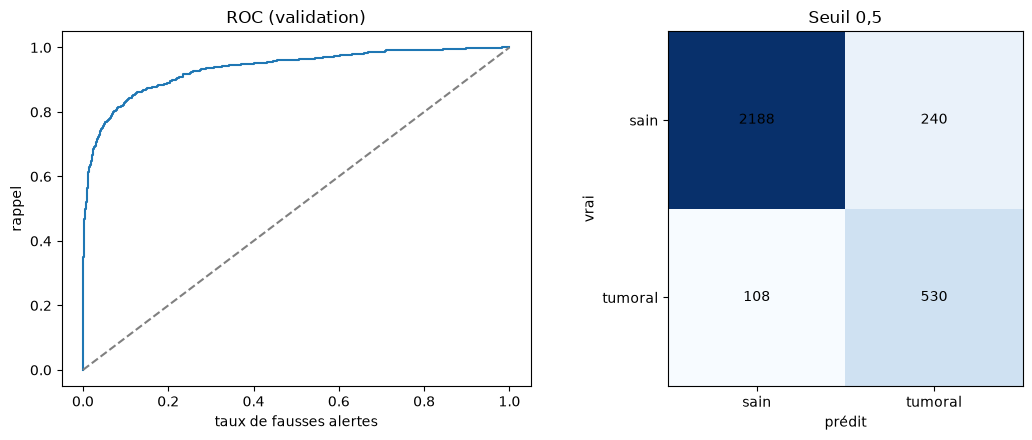

In [9]:
# Courbe ROC et matrice de confusion au seuil 0,5 (patchs de validation)
taux_fp, taux_vp, _ = roc_curve(predictions_val.y_vrai, predictions_val.proba)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(taux_fp, taux_vp); axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("taux de fausses alertes"); axes[0].set_ylabel("rappel"); axes[0].set_title("ROC (validation)")
mc = confusion_matrix(predictions_val.y_vrai, (predictions_val.proba >= 0.5).astype(int))
axes[1].imshow(mc, cmap="Blues")
for (i, j), v in np.ndenumerate(mc):
    axes[1].text(j, i, v, ha="center", va="center")
axes[1].set_xticks([0, 1], ["sain", "tumoral"]); axes[1].set_yticks([0, 1], ["sain", "tumoral"])
axes[1].set_xlabel("prédit"); axes[1].set_ylabel("vrai"); axes[1].set_title("Seuil 0,5")
plt.tight_layout()

## 5. Lancement des cartes de chaleur (script)

Le script `cartes_chaleur.py` parcourt tout le tissu des lames de validation puis de test avec un pas de 56 µm (la zone centrale) et enregistre les 512 caractéristiques de chaque patch (pas les probabilités : la régression logistique est appliquée ici afin qu'on puisse la changer sans tout recalculer). Il ne dépend que du niveau retenu.

Dans un terminal, depuis `version_finale` :

```
python cartes_chaleur.py --niveau 1 --max-slides 1      (essai sur une lame : donne le temps par lame)
python cartes_chaleur.py --niveau 1                     (toutes les lames, validation d'abord)
```

## 6. Lames de validation : de la carte de chaleur à la classe de la lame

Nous réalisons les mêmes étapes que le prototype : probabilité de chaque case, seuil, comblement des trous, lésions (cases voisines), plus grande dimension de chaque lésion, classe de la lame d'après la plus grande lésion. 

Un ajout est réalisé du fait des résultats obtenus en validation : nous choisissons d'ignorer les lésions trop petites (voir partie 6.2.). 

Le corrigé de chaque case vient des annotations XML (pour les lames annotées) ou vaut 0 partout (pour les lames négatives).

In [37]:
VOISINS_8 = np.ones((3, 3), dtype=int)

_cache_cartes = {}

def charger_carte(nom, classifieur):
    """Relit les caractéristiques d'une lame (script cartes_chaleur.py) et construit sa carte de probabilités (une grille de nombres).
    Gardée en mémoire car la relire pour chaque seuil testé serait lent."""
    cle = (nom, id(classifieur), NIVEAU_RETENU)
    if cle in _cache_cartes:
        return _cache_cartes[cle]
    d = dict(np.load(DOSSIER_CARTES / f"niveau_{NIVEAU_RETENU}" / f"{nom}.npz"))
    pas0, patch0 = int(d["pas0"]), int(d["patch0"])
    nr, nc = (int(d["H0"]) - patch0) // pas0 + 1, (int(d["W0"]) - patch0) // pas0 + 1
    carte = np.full((nr, nc), np.nan)
    if len(d["r"]):
        carte[d["r"], d["c"]] = classifieur.predict_proba(d["caracteristiques"].astype(np.float32))[:, 1]
    d["carte"] = carte
    d["taille_case_um"] = pas0 * float(d["mpp"])            # une case = la zone centrale, environ 56 µm
    d["decalage0"] = (patch0 - pas0) // 2                   # la case (r, c) commence en (c*pas0 + decalage0, r*pas0 + decalage0)
    _cache_cartes[cle] = d
    return d

def verite_cases(nom, d, sous=8):
    """Corrigé de chaque case : True si la zone centrale contient de la tumeur (contours XML).
    Lame négative : aucune tumeur. Lame positive sans XML : inconnu (None)."""
    ligne = lames[lames.slide == nom].iloc[0]
    nr, nc = d["carte"].shape
    if not isinstance(ligne["xml_path"], str):
        return np.zeros((nr, nc), bool) if ligne["slide_label"] == "negative" else None
    tumeurs, exclus = ep.polygones_xml(ligne["xml_path"])
    pas0, dec = int(d["pas0"]), d["decalage0"]
    # On dessine les contours sur une grille de sous x sous petits carrés par case, puis "au moins un petit carré tumoral"
    image = np.zeros((nr * sous, nc * sous), np.uint8)
    conv = lambda p: np.round((p - dec) * sous / pas0).astype(np.int32)
    if tumeurs:
        cv2.fillPoly(image, [conv(p) for p in tumeurs], 1)
    if exclus:
        cv2.fillPoly(image, [conv(p) for p in exclus], 0)
    return image.reshape(nr, sous, nc, sous).any(axis=(1, 3))

def trouver_lesions(carte, seuil):
    """Seuil + comblement des trous + numérotation des groupes de cases voisines (comme le prototype)."""
    tumoral = ndimage.binary_fill_holes(np.where(np.isnan(carte), 0, carte) >= seuil) # binary_fill_holes bouche les trous
    return ndimage.label(tumoral, structure=VOISINS_8) # ndimage.label numérote les groupes de cases tumorales qui se touchent y compris en diagonale (VOISINS_8).

def plus_grande_dimension_um(masque_lesion, taille_case_um):
    """Plus grande distance entre deux cases de la lésion, en µm (comme le prototype)."""
    bord = masque_lesion & ~ndimage.binary_erosion(masque_lesion)
    cases = np.argwhere(bord)
    if len(cases) == 1:
        return taille_case_um
    return (pdist(cases).max() + 1) * taille_case_um

def mesurer_lesions(lesions, d, verite=None):
    """Une ligne par lésion : nombre de cases, taille, vraie ou fausse (si on a le corrigé)."""
    lignes = []
    for numero, zone in enumerate(ndimage.find_objects(lesions), start=1):
        m = lesions[zone] == numero
        lignes.append({"lesion": numero, "nb_cases": int(m.sum()),
                       "taille_um": plus_grande_dimension_um(m, d["taille_case_um"]),
                       "vraie": bool(verite[zone][m].any()) if verite is not None else None})
    return pd.DataFrame(lignes, columns=["lesion", "nb_cases", "taille_um", "vraie"])

def classer_lame(taille_max_um):
    # Mêmes mots que stages.csv : negative, itc, micro, macro
    if taille_max_um == 0:
        return "negative"
    if taille_max_um <= 200:
        return "itc"
    if taille_max_um <= 2000:
        return "micro"
    return "macro"

def stade_pN(classes):
    """Règles de CAMELYON17 (comme le prototype) : classes des ganglions -> stade pN."""
    nb_macro = classes.count("macro")
    nb_positifs = nb_macro + classes.count("micro")
    if nb_positifs == 0:
        return "pN0(i+)" if "itc" in classes else "pN0"
    if nb_macro == 0:
        return "pN1mi"
    if nb_positifs <= 3:
        return "pN1"
    return "pN2"

def analyser_lame(nom, seuil, classifieur, avec_verite=True, taille_min_um=0):
# Charge la carte, trouve les lésions, calcule la vérité, mesure les lésions, ignore celles qui ne dépassent pas la taille minimale, puis classe la lame. 
# Si la vérité est connue elle compte aussi les cases VP (tumeur trouvée), FP (fausse alerte) et FN (tumeur manquée).
    d = charger_carte(nom, classifieur)
    lesions, nb = trouver_lesions(d["carte"], seuil)
    verite = verite_cases(nom, d) if avec_verite else None
    tab = mesurer_lesions(lesions, d, verite)
    gardees = tab[tab.taille_um > taille_min_um]
    taille_max = gardees.taille_um.max() if len(gardees) else 0
    res = {"lame": nom, "nb lésions": len(gardees), "nb lésions ignorées": len(tab) - len(gardees), 
           "plus grande lésion (mm)": round(taille_max / 1000, 2), "classe prédite": classer_lame(taille_max)}
    if verite is not None:
        tissu = ~np.isnan(d["carte"])
        predit = tissu & (np.where(tissu, d["carte"], 0) >= seuil)
        vraie = verite & tissu
        res.update({"cases VP": int((predit & vraie).sum()), "cases FP": int((predit & ~vraie).sum()),
                    "cases FN": int((~predit & vraie).sum()),
                    "plus grande fausse lésion (mm)": round(gardees[gardees.vraie == False].taille_um.max() / 1000, 2)
                    if (gardees.vraie == False).any() else 0.0})
    return res, d, lesions, tab, verite

def afficher_carte(nom, d, verite=None, titre="", ax=None):
    """La lame (aperçu), la carte de probabilités par-dessus et le contour de la vraie tumeur s'il est connu."""
    # Code couleur (20/11) : la carte montre directement la probabilité de tumeur de chaque case, SANS seuil
    # (le seuil n'intervient qu'ensuite, dans trouver_lesions). Échelle "jet" de 0 à 1 : bleu foncé = probabilité faible,
    # vert vers 0,5, jaune puis orange en montant, rouge foncé = probabilité proche de 1. Carte à moitié transparente
    # (alpha 0,5) posée sur l'aperçu de la lame ; les cases sans tissu ne sont pas coloriées.
    ax = ax or plt.subplots(figsize=(8, 8))[1]
    W0, H0 = int(d["W0"]), int(d["H0"])
    pas0, dec = int(d["pas0"]), d["decalage0"]
    carte = d["carte"]
    etendue = (dec, dec + carte.shape[1] * pas0, dec + carte.shape[0] * pas0, dec)
    ax.imshow(d["apercu"], extent=(0, W0, H0, 0))
    im = ax.imshow(np.ma.masked_invalid(carte), extent=etendue, cmap="jet", vmin=0, vmax=1, alpha=0.5, interpolation="nearest")
    if verite is not None and verite.any():
        ax.contour(np.arange(carte.shape[1]) * pas0 + dec + pas0 / 2, np.arange(carte.shape[0]) * pas0 + dec + pas0 / 2,
                   verite, levels=[0.5], colors="black", linewidths=1)
    ax.set_title(titre or nom, fontsize=9); ax.axis("off")
    return im

### 6.1 Cartes de chaleur des lames de validation

Nous affichons l'aperçu des cartes de chaleur pour les 10 lames de validation.

Contour noir = vraie tumeur (annotations). Les lames négatives de validation montrent directement les fausses alertes.

La carte montre la probabilité de tumeur de chaque case. Bleu = probabilité faible, vert vers 0,5, jaune puis rouge en approchant de 1 (échelle à droite de la figure). Les cases sans tissu ne sont pas coloriées.

Rappel sur la carte de chaleur : nousa vons choisi un pas de 56 micromètres. Ainsi, chaque point de la lame se trouve au centre d’un patch donc là où le modèle a appris à reconnaître la tumeur : aucune lésion n’est vue uniquement en bord de patch. Le modèle n’ayant pas appris à ignorer la tumeur située au bord, les cases voisines d’une tumeur peuvent aussi être prédites tumorales, ce qui agrandit légèrement les lésions.


10 lames de validation sur 10 ont leur carte


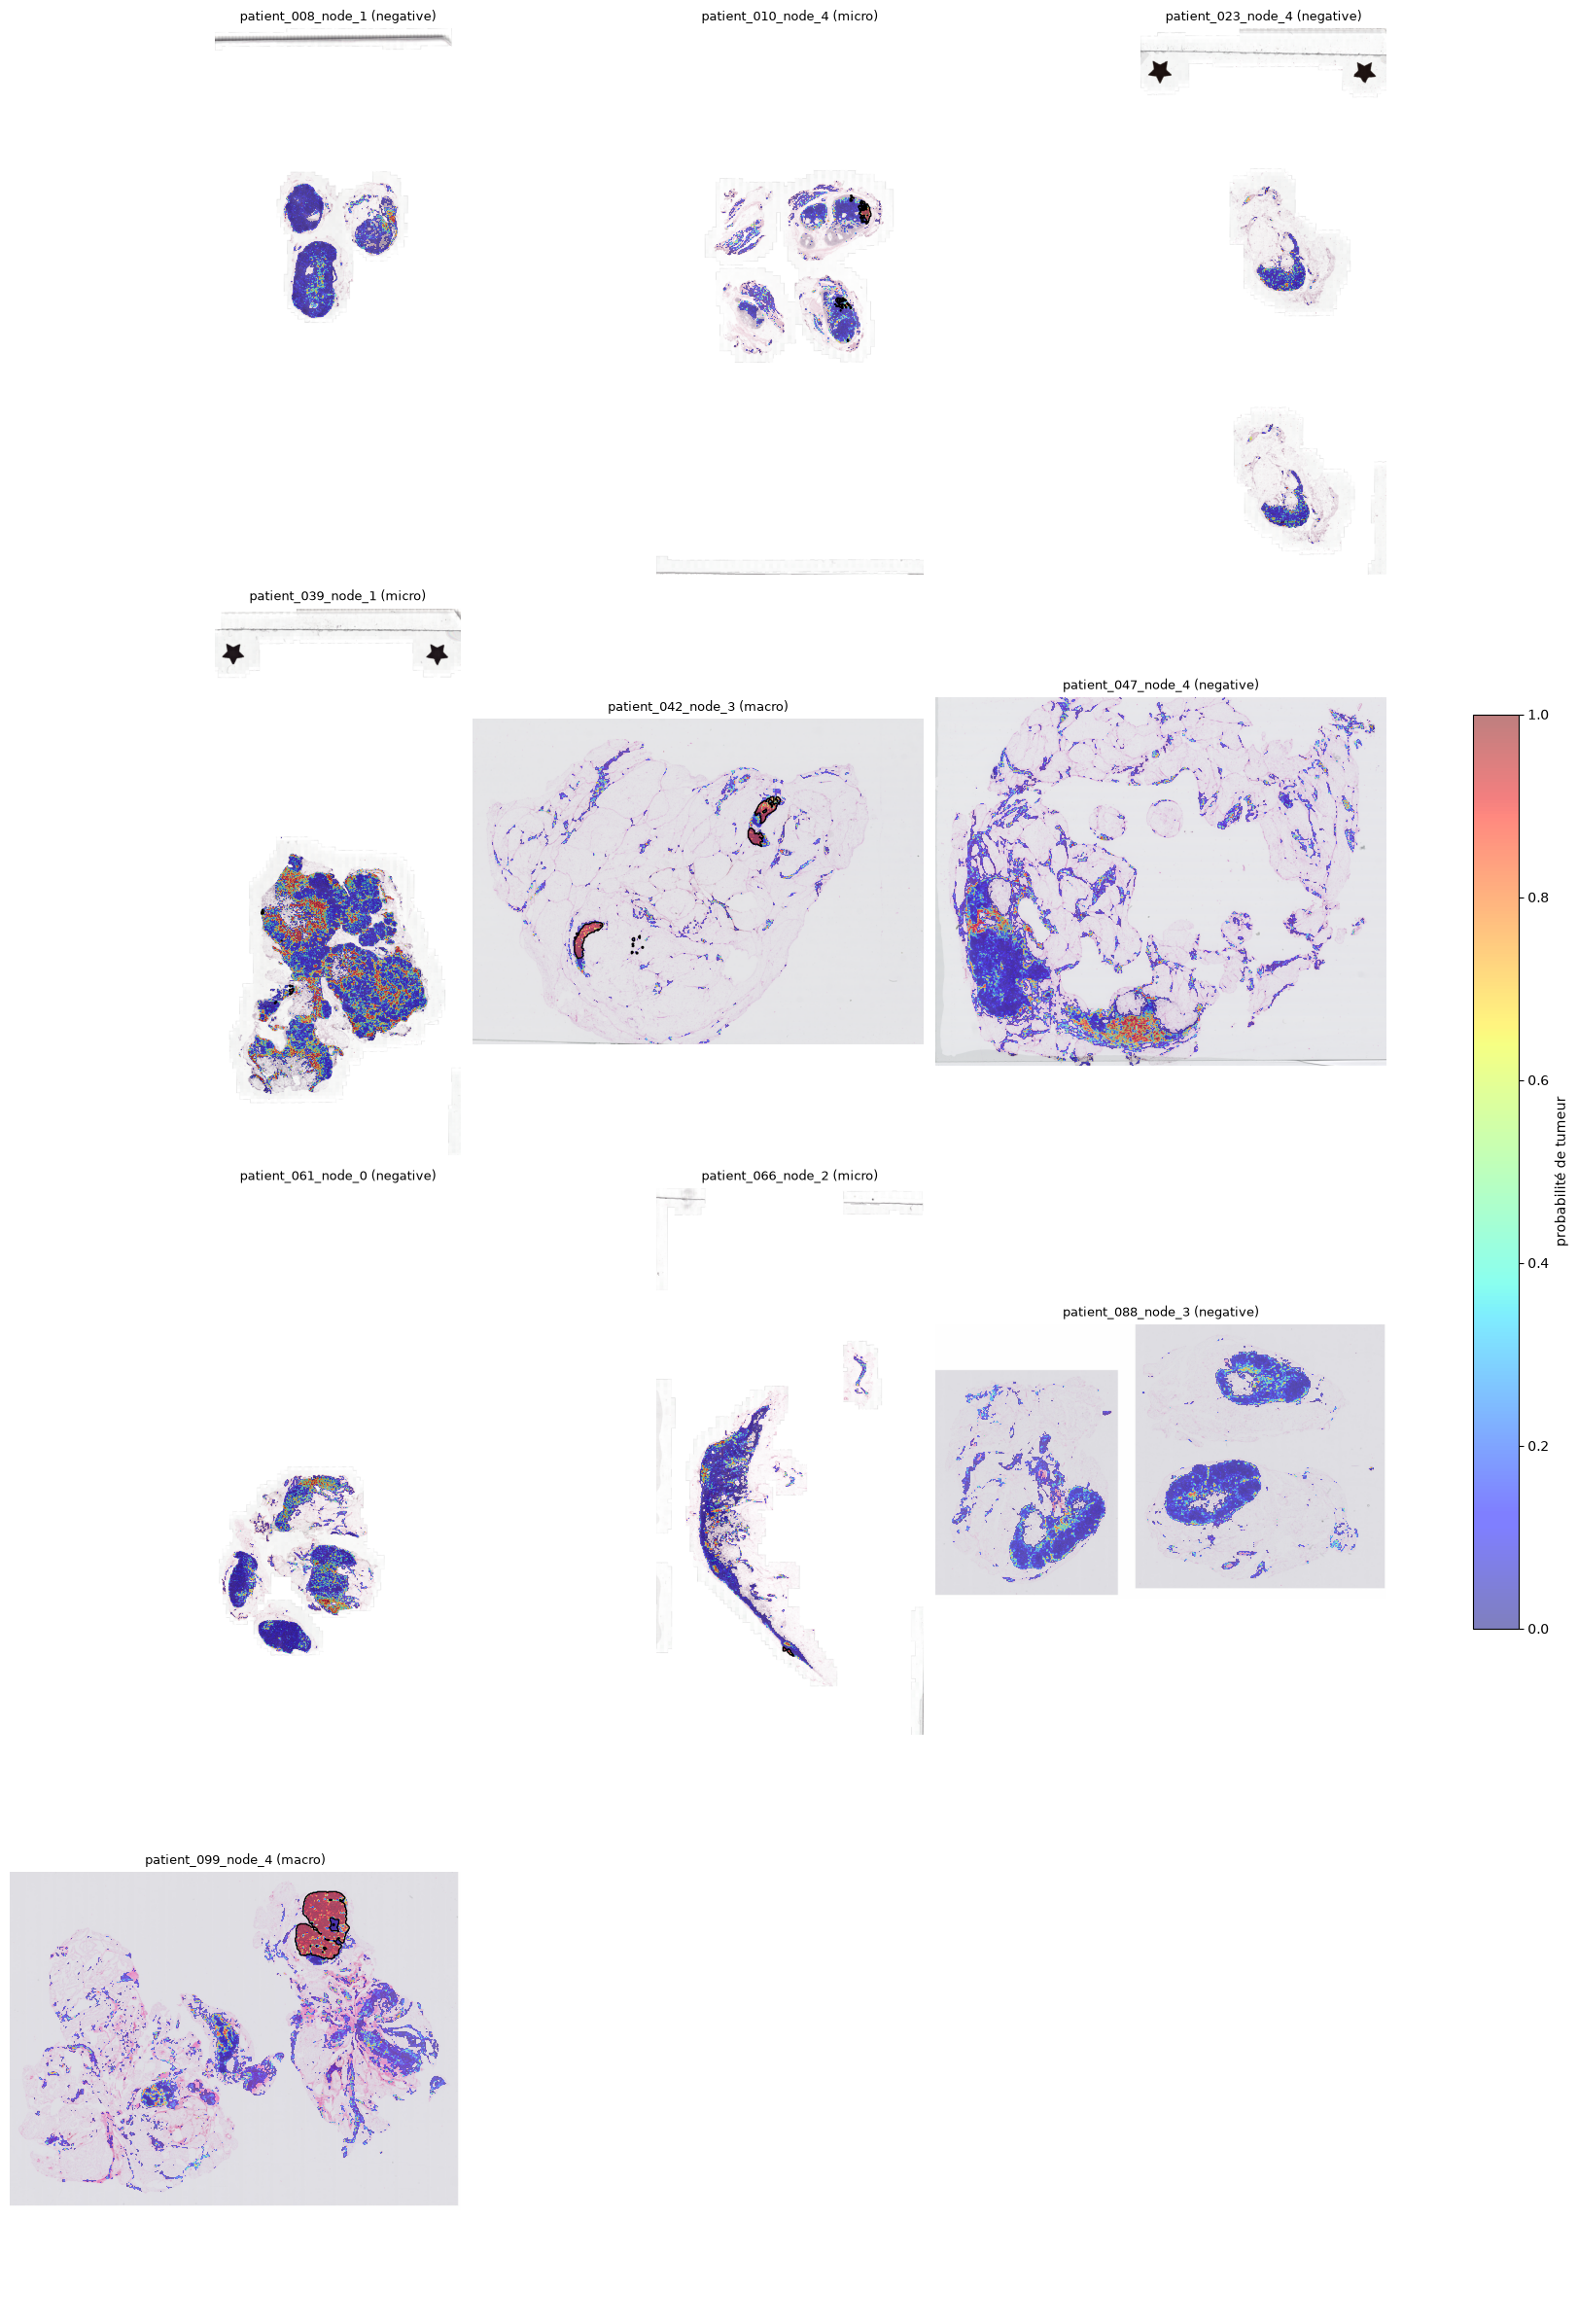

In [38]:
classifieur = joblib.load(DOSSIER_RESULTATS / "classifieur_final.joblib")
lames_val = lames[lames.set == "validation"]
faites = [n for n in lames_val.slide if (DOSSIER_CARTES / f"niveau_{NIVEAU_RETENU}" / f"{n}.npz").exists()]
print(len(faites), "lames de validation sur", len(lames_val), "ont leur carte")
n = len(faites)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(18, 6 * ((n + 2) // 3)), squeeze=False)   # 20/11 : 3 lames par ligne (avant 5) pour mieux voir
for ax, nom in zip(axes.ravel(), faites):
    d = charger_carte(nom, classifieur)
    vraie = lames_val[lames_val.slide == nom].slide_label.iloc[0]
    im = afficher_carte(nom, d, verite_cases(nom, d), f"{nom} ({vraie})", ax)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.4, label="probabilité de tumeur")   # 20/11 : légende des couleurs

Il apparait que :
- Les grosses tumeurs (patient_042_node_3 et patient_099_node_4) sont bien repérées : le rouge remplit les contours annotés. Cela confirme aussi que la carte est bien alignée sur la lame.
- Les lames négatives montrent des fausses alertes surtout patient_047_node_4 (une bande en bas de la lame) et patient_061_node_0 (des taches).

Ces fausses alertes forment de petites lésions qui posent problème pour classer les lames.

### 6.2 Choix du seuil de la carte

Comme noté après le prototype : le seuil choisi sur les patchs sélectionnés (95 % de rappel donc "sur 100 patchs tumoraux, 95 trouvés" sur les patchs) donnait trop de fausses alertes sur la lame de validation entière (où il y avait beaucoup plus de tissu sain). 

On choisit donc le seuil sur les lames de validation : celui qui classe correctement le plus de lames et, à égalité, celui qui fait le moins de fausses alertes (car c'est le problème majeur observé en pratique).

In [27]:
SEUILS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
resultats_seuils = []
for seuil in SEUILS:
    lignes = []
    for nom in faites:
        res, *_ = analyser_lame(nom, seuil, classifieur, taille_min_um=0)   # 20/11 : seuil choisi sans taille minimale
        res["vraie classe"] = lames_val[lames_val.slide == nom].slide_label.iloc[0]
        lignes.append(res)
    t = pd.DataFrame(lignes)
    resultats_seuils.append({"seuil": seuil,
                             "lames bien classées": int((t["classe prédite"] == t["vraie classe"]).sum()),
                             "sur": len(t),
                             "cases FP (fausses alertes)": int(t["cases FP"].sum()),
                             "cases FN (tumeur manquée)": int(t["cases FN"].sum()),
                             "rappel des cases": round(t["cases VP"].sum() / max(1, t["cases VP"].sum() + t["cases FN"].sum()), 3)})
tableau_seuils = pd.DataFrame(resultats_seuils)
display(tableau_seuils)
meilleur = tableau_seuils.sort_values(["lames bien classées", "cases FP (fausses alertes)"], ascending=[False, True]).iloc[0]
print("Seuil proposé :", meilleur.seuil)

,seuil,lames bien classées,sur,cases FP (fausses alertes),cases FN (tumeur manquée),rappel des cases
0,0.50,4,10,27251,754,0.855
1,0.60,4,10,19786,933,0.821
2,0.70,4,10,13685,1158,0.777
3,0.80,4,10,8360,1470,0.717
4,0.90,5,10,3607,2052,0.605
5,0.95,4,10,1464,2658,0.489


Seuil proposé : 0.9


In [ ]:
# Détail des lames de validation au seuil proposé (à regarder avant de figer)
SEUIL_LAME = float(meilleur.seuil) # on peut le remplacer à la main après avoir regardé le tableau
lignes = []
for nom in faites:
    res, *_ = analyser_lame(nom, SEUIL_LAME, classifieur, taille_min_um=0)
    l = lames_val[lames_val.slide == nom].iloc[0]
    res.update({"centre": int(l.center), "vraie classe": l.slide_label})
    lignes.append(res)
synthese_val = pd.DataFrame(lignes)
synthese_val

,lame,nb lésions,nb lésions ignorées,plus grande lésion (mm),classe prédite,cases VP,cases FP,cases FN,plus grande fausse lésion (mm),centre,vraie classe
0,patient_008_node_1,10,0,0.45,micro,0,25,0,0.45,0,negative
1,patient_010_node_4,13,0,1.01,micro,110,10,333,0.11,0,micro
2,patient_023_node_4,19,0,0.21,micro,0,36,0,0.21,1,negative
3,patient_039_node_1,647,0,1.61,micro,21,3030,47,1.61,1,micro
4,patient_042_node_3,28,0,2.96,macro,744,15,524,0.06,2,macro
5,patient_047_node_4,108,0,0.56,micro,0,266,0,0.56,2,negative
6,patient_061_node_0,56,0,0.53,micro,0,129,0,0.53,3,negative
7,patient_066_node_2,33,0,0.36,micro,13,69,48,0.36,3,micro
8,patient_088_node_3,8,0,0.11,itc,0,10,0,0.11,4,negative
9,patient_099_node_4,26,0,4.54,macro,2258,17,1100,0.11,4,macro


Ce tableau présente le détail des 10 lames au seuil de 0,9 et présente :
- nb lésions : le nombre de groupes de cases au-dessus de 0,9 (après comblement des trous)
- nb lésions ignorées : celles qui sont trop petites pour compter. Ici 0 partout car nous gardons toutes les lésions trouvées, sans taille minimale.
- plus grande lésion (mm) : la plus grande d’après nos mesures. C’est elle qui décide donc de la classe classe prédite.
- cases VP : cases trouvées et vraiment tumorales
- cases FP : cases trouvées mais saines (fausses alertes)
- cases FN : vraie tumeur manquée
- plus grande fausse lésion (mm) : la plus grande lésion faite uniquement de cases saines
- vraie classe


On observe que :
- Toutes les lames négatives sont fausses à cause de leurs fausses lésions. Elles n’ont aucune case VP mais 10 à 266 cases FP. Leur plus grande fausse lésion va de 0,11 à 0,56 mm.
- Les positives sont justes même avec beaucoup de cases tumorales manquées. Par exemple, 099 (qui est macro) a 1 100 cases FN, mais sa plus grande lésion fait 4,54 mm donc elle reste macro. C’est pour ça qu’un seuil haut n'apparait pas si gênant pour les grosses tumeurs : on perd une partie de la tumeur mais la plus grande lésion reste assez grande pour garder la bonne classe.
- Les petites lésions sont mal trouvées. Par exemple, 010 (qui est micro) a 333 cases FN pour 110 VP et 066 (micro aussi) a 48 FN pour 13 VP. C’est la limite pour les micro-métastases.
- 039 est un cas à part avec 3 030 cases FP pour 21 VP : le modèle voit de la tumeur un peu partout. Elle est classée micro, sa bonne classe, mais sa plus grande lésion est une fausse lésion (elle est juste par chance).

In [ ]:
# Diagnostic : toutes les lésions des lames de validation au seuil retenu (vraies et fausses)

lignes = []
for nom in faites:
    res, d, lesions, tab, verite = analyser_lame(nom, SEUIL_LAME, classifieur, taille_min_um=0)
    carte = np.nan_to_num(d["carte"])
    for _, les in tab.iterrows():
        m = lesions == les.lesion
        lignes.append({"lame": nom, "vraie classe": lames_val[lames_val.slide == nom].slide_label.iloc[0],
                       "vraie lésion": les.vraie, "nb_cases": les.nb_cases, "taille (mm)": round(les.taille_um / 1000, 2),
                       "proba max": round(float(carte[m].max()), 3), "proba moyenne": round(float(carte[m].mean()), 3)})
toutes = pd.DataFrame(lignes)
display(toutes.groupby("vraie lésion")[["nb_cases", "taille (mm)", "proba max", "proba moyenne"]].describe().T)
display(toutes.sort_values("taille (mm)", ascending=False).groupby("lame").head(3))

vraie lésion              False        True 
nb_cases      count  907.000000    41.000000
              mean     4.028666    82.829268
              std     10.523770   376.737170
              min      1.000000     1.000000
              25%      1.000000     1.000000
              50%      2.000000     2.000000
              75%      3.000000     9.000000
              max    228.000000  2397.000000
taille (mm)   count  907.000000    41.000000
              mean     0.143043     0.415854
              std      0.147165     0.847473
              min      0.060000     0.060000
              25%      0.060000     0.060000
              50%      0.110000     0.110000
              75%      0.170000     0.310000
              max      1.610000     4.540000
proba max     count  907.000000    41.000000
              mean     0.945045     0.960878
              std      0.027673     0.028977
              min      0.900000     0.902000
              25%      0.921000     0.945000
              50%      0.943000     0.955000
              75%      0.969000     0.987000
              max      0.998000     1.000000
proba moyenne count  907.000000    41.000000
              mean     0.933204     0.944537
              std      0.018873     0.017604
              min      0.900000     0.902000
              25%      0.918000     0.934000
              50%      0.934000     0.949000
              75%      0.947000     0.954000
              max      0.986000     0.979000

,lame,vraie classe,vraie lésion,nb_cases,taille (mm),proba max,proba moyenne
922,patient_099_node_4,macro,True,2397,4.54,1.000,0.952
710,patient_042_node_3,macro,True,376,2.96,0.999,0.960
148,patient_039_node_1,micro,False,130,1.61,0.994,0.940
251,patient_039_node_1,micro,False,228,1.45,0.997,0.934
702,patient_042_node_3,macro,True,109,1.44,0.999,0.966
705,patient_042_node_3,macro,True,206,1.31,0.999,0.968
160,patient_039_node_1,micro,False,40,1.07,0.997,0.953
11,patient_010_node_4,micro,True,116,1.01,1.000,0.946
773,patient_047_node_4,negative,False,16,0.56,0.972,0.933
866,patient_061_node_0,negative,False,20,0.53,0.991,0.942


On observe que :
- Il y a beaucoup plus de fausses lésions que de vraies : 907 fausses contre 41 vraies sur les 10 lames.
- La probabilité moyenne est semblable pour les fausses et vraies lésions (moyenne de 0,945 pour les fausses et 0,961 pour les vraies) et les fausses montent jusqu’à 0,998. Un critère de probabilité ne servirait donc à rien.
- La taille les sépare en partie. La plupart des fausses lésions sont petites (75 % font 0,17 mm ou moins) et, dans les lames négatives, la plus grande fausse lésion fait 0,56 mm. Les vraies lésions qui décident de la classe des positives sont plus grandes (1,01 à 4,54 mm).
Cette séparation n'est cependant pas parfaite : beaucoup de vraies lésions sont aussi toutes petites et 039 a de fausses lésions de 1 à 1,6 mm.

> On a donc un modèle qui trouve à tord de petites lésions dans des zones saines et qui, en revanche, ne trouve pas non plus de vraies petites lésions tumorales. C'est le signe que notre modèle manque de performance et n'utilise pas des "critères" '(les caractéristiques de ResNet18) optimisés pour bien détecter les celulles tumorales. 

> Changer le seuil ne ferait que déplacer les erreurs d'un côté à l'autre (plus de fausses alertes ou plus de tumeurs manquées).

> **Nous proposons donc d'ajouter une règle à notre classement des lames : toute lésion sous une certaine taille ne sera pas retenue.**

Nous choisissons cette taille sur la validation.

Notons que cette règle implique de renoncer à détecter les ITC plus petites que la taille minimale (0,2 mm au plus) : une lame ITC sera donc classée négative, et une patiente pN0(i+) sera   prédite pN0. On perdra également les micro-métastases plus petites que la taille minimale.

Par ailleurs, elle ne rend pas le modèle meilleur : elle supprime les fausses petites lésions mais elle ne retrouve pas les vraies petites lésions manquées.

On fait tout de même ce choix pour plusieurs raisons :
- Sans elle, toutes les lames négatives de validation sont classées ITC ou micro et le stade pN est faux.
- La vraie solution serait d'améliorer le modèle de patch (réentraîner ResNet18 sur des lames ou partir d'un modèle pré-entraîné sur l'histologie par exemple) mais cela était hors de notre portée dans le temps du projet. Nous choisissons cette solution simple et transparente en attendant un meilleur modèle.

#### Taille minimale des lésions


On choisit donc d'ignorer les lésions de X mm ou moins. X est choisi sur la validation, au seuil retenu de 0,9. Nous testons des valeurs d'au moins 0,2 mm (la limite ITC / micro) car nous choisissons de renoncer totalement aux ITC.

Notre règle pour choisir est la suivante : le plus de lames bien classées et, à égalité, la plus petite valeur.

La ligne 0 (aucune lésion ignorée) sert seulement de comparaison.

In [30]:
TAILLES_MIN_MM = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
lignes = []
for taille_mm in TAILLES_MIN_MM:
    t = []
    for nom in faites:
        res, *_ = analyser_lame(nom, SEUIL_LAME, classifieur, taille_min_um=taille_mm * 1000)
        res["vraie classe"] = lames_val[lames_val.slide == nom].slide_label.iloc[0]
        t.append(res)
    t = pd.DataFrame(t)
    juste = t["classe prédite"] == t["vraie classe"]
    negative = t["vraie classe"] == "negative"
    lignes.append({"taille min (mm)": taille_mm, "lames bien classées": int(juste.sum()), "sur": len(t),
                   "négatives justes": f"{int(juste[negative].sum())}/{int(negative.sum())}",
                   "positives justes": f"{int(juste[~negative].sum())}/{int((~negative).sum())}"})
tableau_tailles = pd.DataFrame(lignes)
display(tableau_tailles)

candidates = tableau_tailles[tableau_tailles["taille min (mm)"] >= 0.2]
meilleure = candidates.sort_values(["lames bien classées", "taille min (mm)"], ascending=[False, True]).iloc[0]
TAILLE_MIN_UM = float(meilleure["taille min (mm)"]) * 1000
print("Taille minimale retenue :", TAILLE_MIN_UM / 1000, "mm (les lésions de cette taille ou moins sont ignorées)")


,taille min (mm),lames bien classées,sur,négatives justes,positives justes
0,0.0,5,10,0/5,5/5
1,0.2,6,10,1/5,5/5
2,0.4,6,10,2/5,4/5
3,0.6,9,10,5/5,4/5
4,0.8,9,10,5/5,4/5
5,1.0,9,10,5/5,4/5


Taille minimale retenue : 0.6 mm (les lésions de cette taille ou moins sont ignorées)


In [31]:
# Détail des lames de validation au seuil et à la taille minimale retenus (à regarder avant de figer)
lignes = []
for nom in faites:
    res, *_ = analyser_lame(nom, SEUIL_LAME, classifieur, taille_min_um=TAILLE_MIN_UM)
    l = lames_val[lames_val.slide == nom].iloc[0]
    res.update({"centre": int(l.center), "vraie classe": l.slide_label})
    lignes.append(res)
synthese_val = pd.DataFrame(lignes)
synthese_val["bien classée"] = synthese_val["classe prédite"] == synthese_val["vraie classe"]
synthese_val[["lame", "centre", "vraie classe", "classe prédite", "bien classée", "plus grande lésion (mm)",
              "nb lésions", "nb lésions ignorées"]]


,lame,centre,vraie classe,classe prédite,bien classée,plus grande lésion (mm),nb lésions,nb lésions ignorées
0,patient_008_node_1,0,negative,negative,True,0.00,0,10
1,patient_010_node_4,0,micro,micro,True,1.01,1,12
2,patient_023_node_4,1,negative,negative,True,0.00,0,19
3,patient_039_node_1,1,micro,micro,True,1.61,11,636
4,patient_042_node_3,2,macro,macro,True,2.96,3,25
5,patient_047_node_4,2,negative,negative,True,0.00,0,108
6,patient_061_node_0,3,negative,negative,True,0.00,0,56
7,patient_066_node_2,3,micro,negative,False,0.00,0,33
8,patient_088_node_3,4,negative,negative,True,0.00,0,8
9,patient_099_node_4,4,macro,macro,True,4.54,1,25


L'effet de notre choix sur les lames de validation est le suivant :
- Les 5 lames négatives sont reclassées correctement alors que sans filtre chacune avait de petites fausses lésions qui la faisaient classer ITC ou micro.
- Nous perdons cependant 1 micro-métastase qui passe en négatif (`patient_066_node_2` pour qui la plus grande lésion détectée ne fait que 0,36 mm).

> A noter : nous ne pouvons pas mesurer la perte sur les ITC en validation car elle ne contient aucune lame ITC et la valeur est choisie sur 10 lames de validation uniquement.

> Nous renonçons donc à détecter les ITC ainsi que les micro-métastases de moins de 0,6 mm.


### 6.3 Fausses alertes de la validation (Grad-CAM)

Nous présentons ici les cases prédites tumorales hors de la vraie tumeur les plus "sûres" pour le modèle, avec leur Grad-CAM.

3607 cases de fausse alerte en validation ; {'patient_008_node_1': 25, 'patient_010_node_4': 10, 'patient_023_node_4': 36, 'patient_039_node_1': 3030, 'patient_042_node_3': 15, 'patient_047_node_4': 266, 'patient_061_node_0': 129, 'patient_066_node_2': 69, 'patient_088_node_3': 10, 'patient_099_node_4': 17}


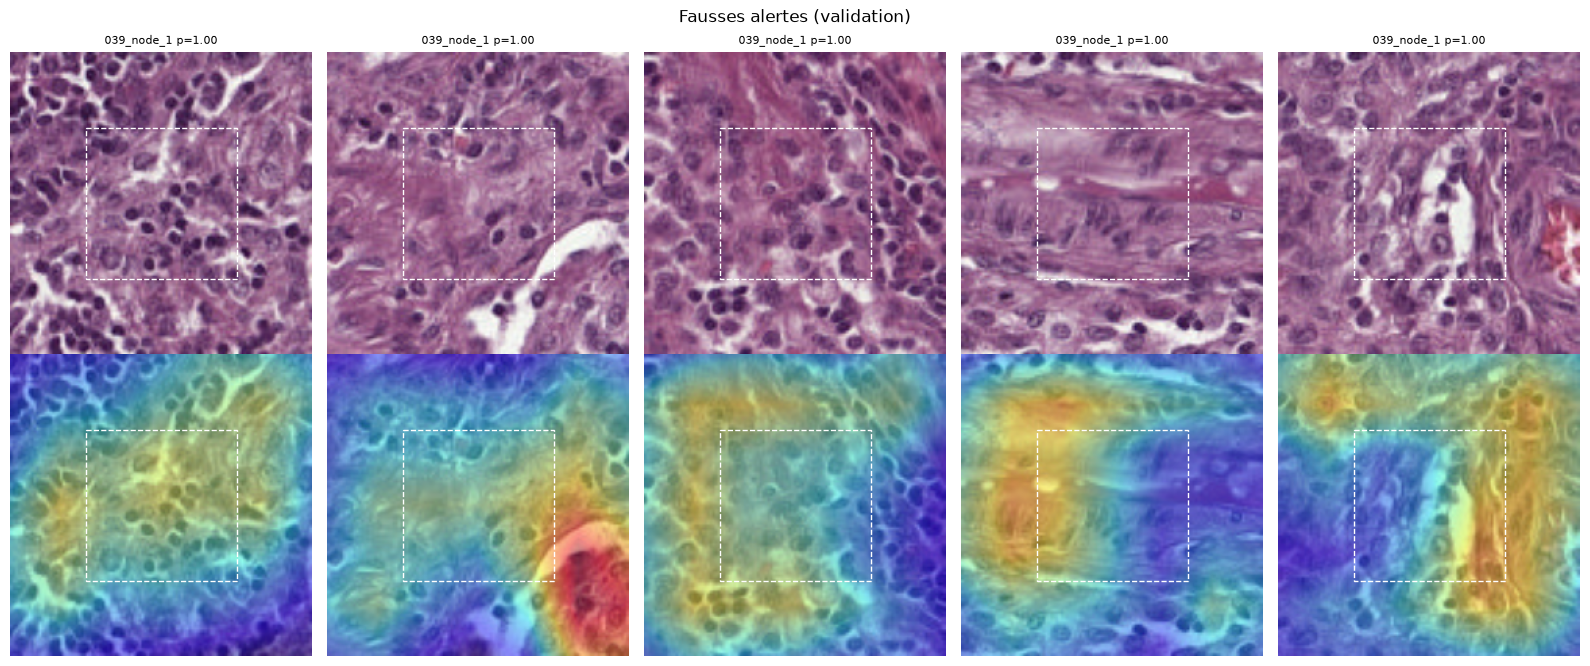

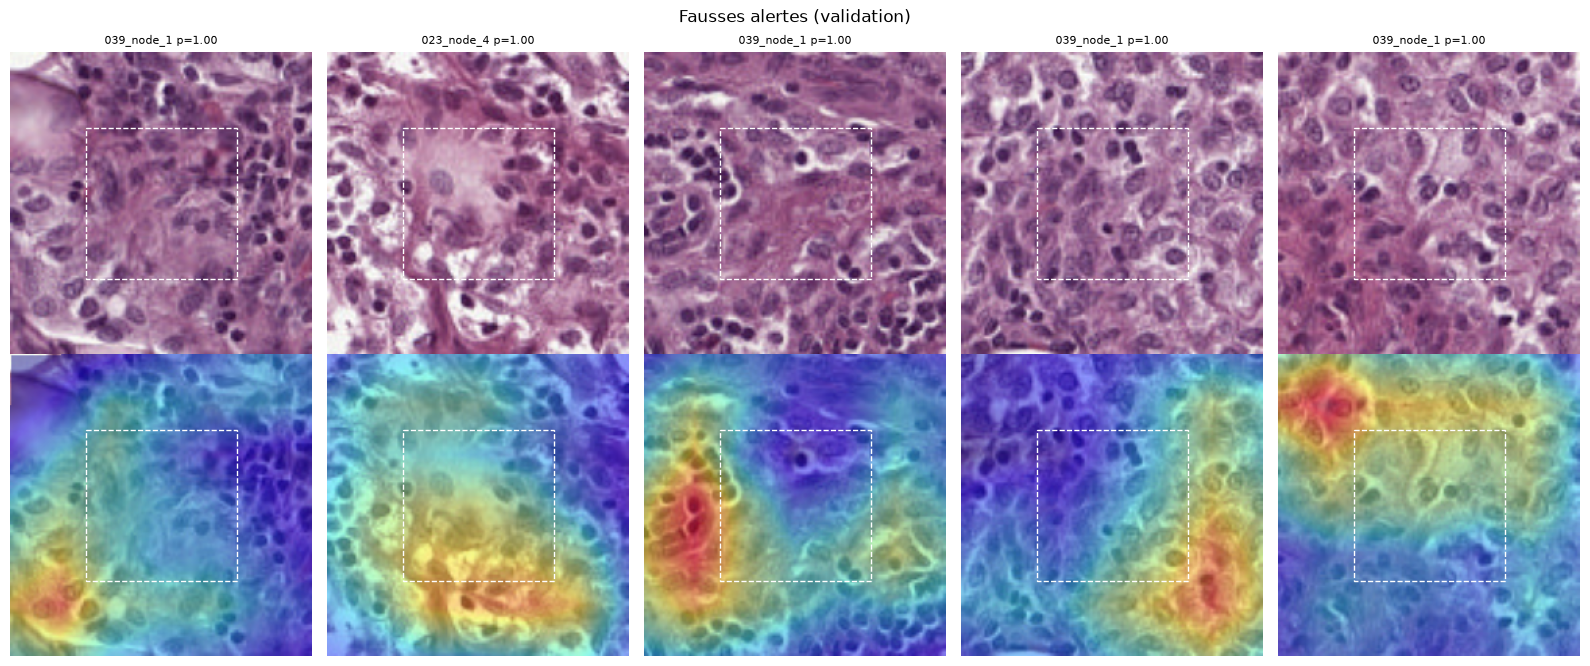

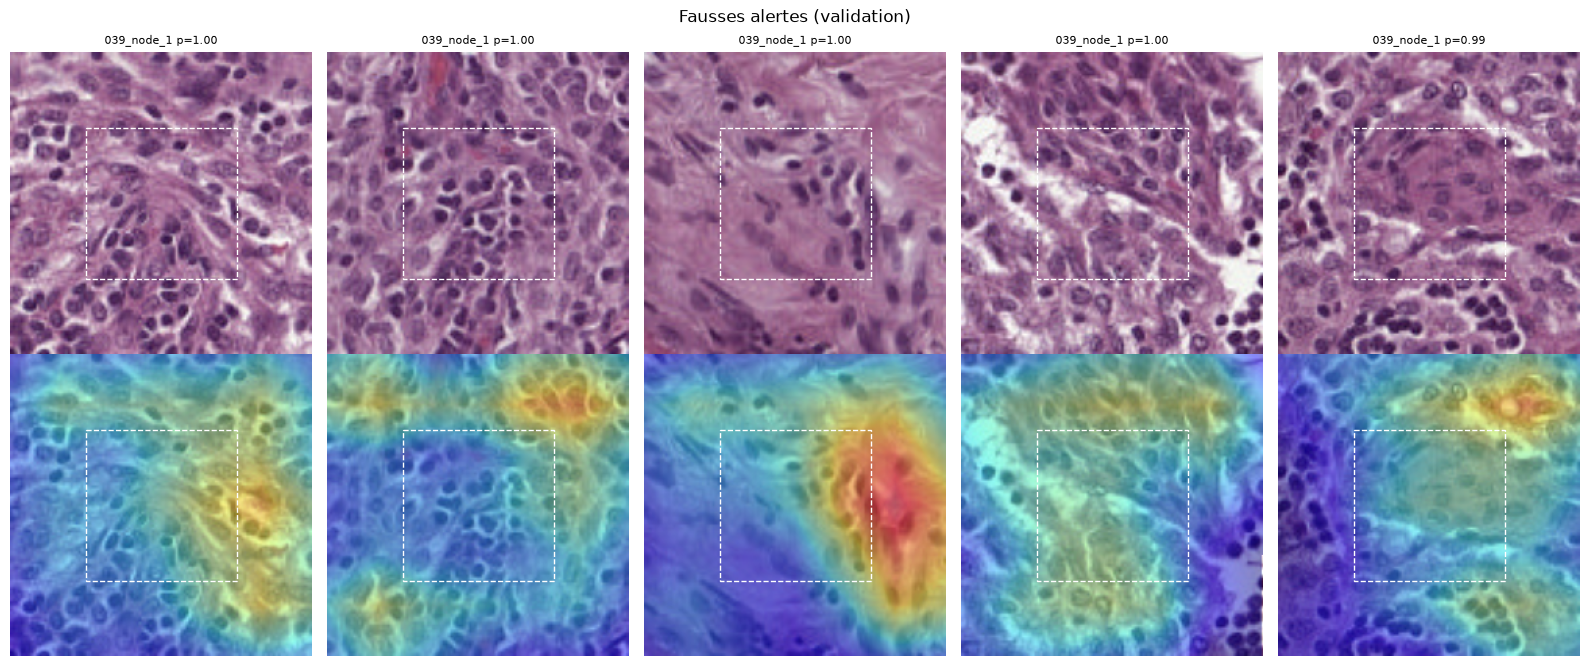

In [32]:
extracteur = mp.extracteur_cartes(resnet)
poids_cartes = classifieur[-1].coef_[0] / classifieur[0].scale_

def lire_patch(nom, r, c, d):
    """Relit le patch (r, c) d'une lame, exactement comme le script (surface fixe, remis à 224 pixels)."""
    slide = cd.open_slide(lames[lames.slide == nom].tif_path.iloc[0])
    L = int(d["niveau"]); taille = max(1, int(round(int(d["patch0"]) / slide.level_downsamples[L])))
    img = cd.read_patch(slide, int(c) * int(d["pas0"]), int(r) * int(d["pas0"]), size=taille, level=L)
    if taille != 224:
        img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA if taille > 224 else cv2.INTER_LINEAR)
    return img

def calculer_gradcam(images):
    import torch
    lot = torch.stack([mp.preparation(im) for im in images]).to(appareil)
    with torch.no_grad():
        cartes = extracteur(lot).cpu().numpy()                      # (n, 512, 7, 7)
    cams = np.maximum((poids_cartes[None, :, None, None] * cartes).sum(axis=1), 0)
    return np.stack([ndimage.zoom(c, 224 / c.shape[0], order=1) for c in cams])

def afficher_gradcam(images, cams, titres, titre_figure, vmax=None):
    n = len(images)
    if n == 0:
        print("Rien à afficher :", titre_figure); return
    vmax = vmax or cams.max()
    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.8), squeeze=False)
    debut = (224 - 112) // 2
    for j in range(n):
        axes[0, j].imshow(images[j]); axes[0, j].set_title(titres[j], fontsize=8)
        axes[1, j].imshow(images[j])
        axes[1, j].imshow(np.ma.masked_where(cams[j] <= 0, cams[j]), cmap="jet", vmin=0, vmax=vmax, alpha=0.45)
        for i in range(2):
            axes[i, j].add_patch(Rectangle((debut, debut), 112, 112, fill=False, edgecolor="white", linestyle="--"))
            axes[i, j].axis("off")
    plt.suptitle(titre_figure); plt.tight_layout()

# Toutes les fausses alertes des lames de validation, triées de la plus sûre à la moins sûre
fausses = []
for nom in faites:
    d = charger_carte(nom, classifieur)
    verite = verite_cases(nom, d)
    if verite is None:
        continue
    r, c = np.nonzero(np.where(np.isnan(d["carte"]), 0, d["carte"]) >= SEUIL_LAME)
    for rr, cc in zip(r, c):
        if not verite[rr, cc]:
            fausses.append({"lame": nom, "r": rr, "c": cc, "proba": d["carte"][rr, cc]})
fausses = pd.DataFrame(fausses, columns=["lame", "r", "c", "proba"]).sort_values("proba", ascending=False)
print(len(fausses), "cases de fausse alerte en validation ;", fausses.groupby("lame").size().to_dict())
choix = fausses.head(15)
images = [lire_patch(l.lame, l.r, l.c, charger_carte(l.lame, classifieur)) for l in choix.itertuples()]
if images:
    cams = calculer_gradcam(images)
    for debut in range(0, len(images), 5):
        afficher_gradcam(images[debut:debut + 5], cams[debut:debut + 5],
                         [f"{l.lame[8:]} p={l.proba:.2f}" for l in choix.iloc[debut:debut + 5].itertuples()],
                         "Fausses alertes (validation)", cams.max())

### 6.4 On fige tous les réglages

In [39]:
reglages = {"variante": VARIANTE_RETENUE, "niveau": NIVEAU_RETENU, "seuil_lame": SEUIL_LAME,
            "taille_min_lesion_um": TAILLE_MIN_UM,   # 20/11
            "C": float(classifieur[-1].C), "date": time.strftime("%Y-%m-%d %H:%M")}
FICHIER_REGLAGES.write_text(json.dumps(reglages, indent=2))
reglages

{'variante': 'retenue',
 'niveau': 2,
 'seuil_lame': 0.9,
 'taille_min_lesion_um': 600.0,
 'C': 0.001,
 'date': '2026-11-20 14:43'}

## 7. Test : classe de chaque lame et stade pN de chaque patiente

Réglages relus dans `resultats/reglages_figes.json`. Vrai stade : celui de `stages.csv` (on vérifie qu'il correspond
au stade recalculé avec nos règles à partir des vraies classes des lames).
Métrique officielle de CAMELYON17 : le **kappa pondéré quadratique** entre stades prédits et vrais
(1 = accord parfait, 0 = comme le hasard ; une erreur de deux stades compte plus qu'une erreur d'un stade).
Avec 8 patientes, il est indicatif : on regarde surtout le détail patiente par patiente.

In [ ]:
reglages = json.loads(FICHIER_REGLAGES.read_text())
classifieur = joblib.load(DOSSIER_RESULTATS / "classifieur_final.joblib")
SEUIL_LAME, NIVEAU_RETENU = reglages["seuil_lame"], reglages["niveau"]
TAILLE_MIN_UM = reglages["taille_min_lesion_um"]   # 20/11
print("Réglages figés :", reglages)

lames_test = lames[lames.set == "test"]
manquantes = [n for n in lames_test.slide if not (DOSSIER_CARTES / f"niveau_{NIVEAU_RETENU}" / f"{n}.npz").exists()]
assert not manquantes, f"Cartes manquantes (relancer cartes_chaleur.py) : {manquantes}"

lignes = []
for l in lames_test.itertuples():
    res, *_ = analyser_lame(l.slide, SEUIL_LAME, classifieur, taille_min_um=TAILLE_MIN_UM)
    res.update({"patiente": l.patient, "centre": int(l.center), "vraie classe": l.slide_label, "annotée": l.annotated})
    lignes.append(res)
resultats_lames = pd.DataFrame(lignes)
resultats_lames["bien classée"] = resultats_lames["classe prédite"] == resultats_lames["vraie classe"]
resultats_lames.to_csv(DOSSIER_RESULTATS / "test_lames.csv", index=False)
resultats_lames[["patiente", "lame", "vraie classe", "classe prédite", "bien classée", "plus grande lésion (mm)", "nb lésions"]]

In [ ]:
# Stade pN de chaque patiente
STADES = ["pN0", "pN0(i+)", "pN1mi", "pN1", "pN2"]
lignes = []
for patiente, g in resultats_lames.groupby("patiente"):
    vrai = lames_test[lames_test.patient == patiente].pN_stage.iloc[0]
    assert stade_pN(list(g["vraie classe"])) == vrai, f"{patiente} : nos règles ne redonnent pas le stade de stages.csv"
    lignes.append({"patiente": patiente, "centre": int(g.centre.iloc[0]), "vrai stade": vrai,
                   "stade prédit": stade_pN(list(g["classe prédite"])),
                   "lames bien classées": f"{int(g['bien classée'].sum())}/{len(g)}",
                   "type": lames_test[lames_test.patient == patiente].raison.iloc[0]})
resultats_patientes = pd.DataFrame(lignes)
resultats_patientes["stade juste"] = resultats_patientes["vrai stade"] == resultats_patientes["stade prédit"]
resultats_patientes.to_csv(DOSSIER_RESULTATS / "test_patientes.csv", index=False)

kappa = cohen_kappa_score(resultats_patientes["vrai stade"].map(STADES.index),
                          resultats_patientes["stade prédit"].map(STADES.index),
                          weights="quadratic", labels=list(range(5)))
print(f"Kappa pondéré quadratique : {kappa:.3f} | stades justes : {resultats_patientes['stade juste'].sum()}/{len(resultats_patientes)}"
      f" | lames bien classées : {resultats_lames['bien classée'].sum()}/{len(resultats_lames)}")
resultats_patientes

In [ ]:
# Lames : classe vraie x classe prédite, et résultats par centre
CLASSES = ["negative", "itc", "micro", "macro"]
display(pd.crosstab(pd.Categorical(resultats_lames["vraie classe"], CLASSES),
                    pd.Categorical(resultats_lames["classe prédite"], CLASSES),
                    rownames=["vraie"], colnames=["prédite"], dropna=False))
display(resultats_lames.groupby("centre")["bien classée"].agg(["sum", "count"])
        .rename(columns={"sum": "lames bien classées", "count": "lames"}))

## 8. Analyse des erreurs : de la patiente aux patchs

Pour chaque patiente au stade faux : ses lames mal classées, leur carte (contour noir = vraie tumeur, connu pour les lames
annotées et les lames négatives), puis les patchs de la lésion qui a décidé de la classe, avec leur Grad-CAM.
Pour les patientes "test partiel" (pN2), le contour n'est pas connu sur les lames positives non annotées.

In [ ]:
for _, p in resultats_patientes[~resultats_patientes["stade juste"]].iterrows():
    mal = resultats_lames[(resultats_lames.patiente == p["patiente"]) & ~resultats_lames["bien classée"]]
    print(f"{p['patiente']} ({p['type']}) : vrai {p['vrai stade']}, prédit {p['stade prédit']} - lames mal classées : {list(mal.lame)}")
    for _, l in mal.iterrows():
        res, d, lesions, tab, verite = analyser_lame(l["lame"], SEUIL_LAME, classifieur, taille_min_um=TAILLE_MIN_UM)
        afficher_carte(l["lame"], d, verite, f"{l['lame']} : vraie {l['vraie classe']}, prédite {res['classe prédite']} "
                       f"({res['plus grande lésion (mm)']} mm)")
        plt.show()
        display(tab.sort_values("taille_um", ascending=False).head(5))
        if len(tab):
            numero = int(tab.sort_values("taille_um", ascending=False).lesion.iloc[0])
            r, c = np.nonzero(lesions == numero)
            ordre = np.argsort(-np.nan_to_num(d["carte"][r, c]))[:5]
            images = [lire_patch(l["lame"], r[i], c[i], d) for i in ordre]
            afficher_gradcam(images, calculer_gradcam(images), [f"p={d['carte'][r[i], c[i]]:.2f}" for i in ordre],
                             f"{l['lame']} : patchs les plus sûrs de la plus grande lésion")
            plt.show()

In [ ]:
# Lésions des lames de test dont on connaît la vérité (lames annotées et lames négatives) : vraies, fausses, ratées
lignes = []
for _, l in resultats_lames.iterrows():
    res, d, lesions, tab, verite = analyser_lame(l["lame"], SEUIL_LAME, classifieur, taille_min_um=TAILLE_MIN_UM)
    if verite is None:
        continue
    vraies_lesions, nb_vraies = ndimage.label(verite, structure=VOISINS_8)
    trouvees = sum(bool((lesions[vraies_lesions == k] > 0).any()) for k in range(1, nb_vraies + 1))
    lignes.append({"lame": l["lame"], "vraie classe": l["vraie classe"],
                   "vraies lésions": nb_vraies, "trouvées": trouvees,
                   "fausses lésions": int((tab.vraie == False).sum()),
                   "fausses lésions gardées": int(((tab.vraie == False) & (tab.taille_um > TAILLE_MIN_UM)).sum()),   # 20/11
                   "cases FP": res["cases FP"], "cases FN": res["cases FN"]})
pd.DataFrame(lignes)